In [ ]:
# ================================================================
# PHASE 3B — CELL 1
# MOUNT GOOGLE DRIVE
# ================================================================

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ================================================================
# PHASE 3B — CELL 2
# IMPORTS AND REPRODUCIBILITY
# ================================================================

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
    cohen_kappa_score
)


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

print("Seed:", SEED)
print("✓ Imports complete.")

Seed: 42
✓ Imports complete.


In [ ]:
# ================================================================
# PHASE 3B — CELL 3
# PATHS
# ================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE2_DIR = (
    PROJECT_DIR /
    "phase2_quantitative"
)

PHASE3_DIR = (
    PROJECT_DIR /
    "phase3_classification"
)

P3A_DIR = (
    PHASE3_DIR /
    "phase3A_label_audit"
)

P3B_DIR = (
    PHASE3_DIR /
    "phase3B_direct_baseline"
)

P3B_CONFIG_DIR = (
    P3B_DIR /
    "configs"
)

P3B_TABLE_DIR = (
    P3B_DIR /
    "tables"
)

P3B_PLOT_DIR = (
    P3B_DIR /
    "plots"
)


for folder in [
    P3B_CONFIG_DIR,
    P3B_TABLE_DIR,
    P3B_PLOT_DIR
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


print("Phase 3B directory:")
print(P3B_DIR)

print("\n✓ Phase 3B directories ready.")

Phase 3B directory:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3B_direct_baseline

✓ Phase 3B directories ready.


In [ ]:
# ================================================================
# PHASE 3B — CELL 4A
# INSPECT PHASE 2 SAVED FILES
# ================================================================

PHASE2_DIR = (
    PROJECT_DIR /
    "phase2_quantitative"
)

assert PHASE2_DIR.exists(), (
    f"Phase 2 directory does not exist:\n{PHASE2_DIR}"
)

print("=" * 72)
print("PHASE 2 DIRECTORY CONTENTS")
print("=" * 72)

for path in sorted(
    PHASE2_DIR.rglob("*")
):
    if path.is_file():
        print(
            path.relative_to(
                PHASE2_DIR
            )
        )

PHASE 2 DIRECTORY CONTENTS
PHASE2_COMPLETE.json
PHASE2_FINAL_RECORD.json
phase2A_measurement_method/configs/phase2A_development_record.json
phase2A_measurement_method/configs/phase2A_geometry_method_decision.json
phase2A_measurement_method/configs/phase2A_measurement_protocol.json
phase2A_measurement_method/tables/ground_truth_geometry_candidates.csv
phase2A_measurement_method/tables/validation_EF_error_decomposition.csv
phase2A_measurement_method/tables/validation_geometry_method_comparison.csv
phase2A_measurement_method/tables/validation_geometry_paired_comparison.csv
phase2A_measurement_method/tables/validation_gt_geometry_candidates.csv
phase2A_measurement_method/tables/validation_gt_vs_pred_quantitative_measurements.csv
phase2A_measurement_method/tables/validation_segmentation_to_measurement_error.csv
phase2B_final_evaluation/configs/phase2B_failure_analysis_record.json
phase2B_final_evaluation/configs/phase2B_final_evaluation_record.json
phase2B_final_evaluation/configs/phase2B_l

In [ ]:
# ================================================================
# PHASE 3B — CELL 4
# VERIFY FROZEN UPSTREAM PIPELINE
# ================================================================

# ---------------------------------------------------------------
# PATHS
# ---------------------------------------------------------------

PHASE2_COMPLETE_PATH = (
    PROJECT_DIR /
    "phase2_quantitative" /
    "PHASE2_COMPLETE.json"
)

PHASE2_FINAL_RECORD_PATH = (
    PROJECT_DIR /
    "phase2_quantitative" /
    "PHASE2_FINAL_RECORD.json"
)

PHASE3A_DECISION_PATH = (
    PROJECT_DIR /
    "phase3_classification" /
    "phase3A_label_audit" /
    "configs" /
    "phase3A_classification_target_decision.json"
)


# ---------------------------------------------------------------
# VERIFY FILES EXIST
# ---------------------------------------------------------------

required_files = {
    "Phase 2 completion marker":
        PHASE2_COMPLETE_PATH,

    "Phase 2 final record":
        PHASE2_FINAL_RECORD_PATH,

    "Phase 3A target decision":
        PHASE3A_DECISION_PATH
}


print("=" * 72)
print("VERIFYING UPSTREAM RECORDS")
print("=" * 72)


for name, path in required_files.items():

    exists = path.exists()

    print(
        f"{name:<30}: "
        f"{'FOUND' if exists else 'MISSING'}"
    )

    if exists:
        print(f"  {path}")


missing_files = [
    str(path)
    for path in required_files.values()
    if not path.exists()
]


assert len(missing_files) == 0, (
    "Required upstream files are missing:\n"
    + "\n".join(missing_files)
)


# ---------------------------------------------------------------
# LOAD RECORDS
# ---------------------------------------------------------------

with open(
    PHASE2_COMPLETE_PATH,
    "r"
) as f:

    phase2_completion = json.load(f)


with open(
    PHASE2_FINAL_RECORD_PATH,
    "r"
) as f:

    phase2_record = json.load(f)


with open(
    PHASE3A_DECISION_PATH,
    "r"
) as f:

    phase3A_decision = json.load(f)


# ---------------------------------------------------------------
# VERIFY PHASE 2 STATUS
# ---------------------------------------------------------------

assert (
    phase2_completion.get("status")
    ==
    "COMPLETE"
), (
    "Phase 2 completion marker does not report COMPLETE."
)


assert (
    phase2_record.get("status")
    ==
    "COMPLETE_AND_FROZEN"
), (
    "Phase 2 final record is not COMPLETE_AND_FROZEN."
)


assert (
    phase2_record.get("phase2_frozen")
    is True
), (
    "Phase 2 final record does not indicate a frozen pipeline."
)


# ---------------------------------------------------------------
# VERIFY PHASE 3A STATUS
# ---------------------------------------------------------------

assert (
    phase3A_decision.get("status")
    ==
    "COMPLETE_AND_FROZEN"
), (
    "Phase 3A target definition is not COMPLETE_AND_FROZEN."
)


assert (
    phase3A_decision.get("target_frozen")
    is True
), (
    "Phase 3A target definition is not frozen."
)


# ---------------------------------------------------------------
# VERIFY EXPECTED CLASS DEFINITIONS
# ---------------------------------------------------------------

expected_classes = {
    "Lower_EF":
        "reference EF <= 40%",

    "Intermediate_EF":
        "40% < reference EF < 50%",

    "Higher_EF":
        "reference EF >= 50%"
}


assert (
    phase3A_decision.get(
        "target_definition"
    )
    ==
    expected_classes
), (
    "Phase 3A class definitions do not match "
    "the expected frozen definitions."
)


# ---------------------------------------------------------------
# FINAL STATUS
# ---------------------------------------------------------------

print("\n" + "=" * 72)
print("UPSTREAM PIPELINE VERIFIED")
print("=" * 72)

print("\nPhase 1 segmentation       : FROZEN")
print("Phase 2 quantitative stage : FROZEN")
print("Phase 3A target definition : FROZEN")

print("\nFrozen Phase 3 classes:")
print("  Lower EF        : <= 40%")
print("  Intermediate EF : >40% and <50%")
print("  Higher EF       : >= 50%")

print(
    "\n✓ No upstream modification is permitted in Phase 3B."
)

print(
    "✓ Ready for direct geometry classification baseline."
)

VERIFYING UPSTREAM RECORDS
Phase 2 completion marker     : FOUND
  /content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/PHASE2_COMPLETE.json
Phase 2 final record          : FOUND
  /content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/PHASE2_FINAL_RECORD.json
Phase 3A target decision      : FOUND
  /content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3A_label_audit/configs/phase3A_classification_target_decision.json

UPSTREAM PIPELINE VERIFIED

Phase 1 segmentation       : FROZEN
Phase 2 quantitative stage : FROZEN
Phase 3A target definition : FROZEN

Frozen Phase 3 classes:
  Lower EF        : <= 40%
  Intermediate EF : >40% and <50%
  Higher EF       : >= 50%

✓ No upstream modification is permitted in Phase 3B.
✓ Ready for direct geometry classification baseline.


In [ ]:
# ================================================================
# PHASE 3B — CELL 5
# LOAD EXACT FROZEN PHASE 2B PATIENT-LEVEL TABLE
# ================================================================

PHASE2B_PATIENT_TABLE_PATH = (
    PROJECT_DIR /
    "phase2_quantitative" /
    "phase2B_final_evaluation" /
    "tables" /
    "final_test_patient_level_errors.csv"
)


assert PHASE2B_PATIENT_TABLE_PATH.exists(), (
    f"Phase 2B patient-level table not found:\n"
    f"{PHASE2B_PATIENT_TABLE_PATH}"
)


phase3B_df = pd.read_csv(
    PHASE2B_PATIENT_TABLE_PATH
)


# ---------------------------------------------------------------
# VERIFY REQUIRED DATA
# ---------------------------------------------------------------

required_columns = [
    "patient_id",
    "reference_EF_pct",
    "GT_EF_pct",
    "PRED_EF_pct"
]


missing_columns = [
    column
    for column in required_columns
    if column not in phase3B_df.columns
]


assert len(missing_columns) == 0, (
    "Missing required columns:\n"
    + str(missing_columns)
)


assert len(phase3B_df) == 50, (
    f"Expected 50 patients, found {len(phase3B_df)}."
)


assert (
    phase3B_df["patient_id"].nunique()
    ==
    50
), "Duplicate patient IDs detected."


assert (
    phase3B_df[
        required_columns
    ]
    .notna()
    .all()
    .all()
), "Missing values detected."


# ---------------------------------------------------------------
# STATUS
# ---------------------------------------------------------------

print("=" * 72)
print("FROZEN PHASE 2B PATIENT TABLE LOADED")
print("=" * 72)

print("\nSource:")
print(PHASE2B_PATIENT_TABLE_PATH)

print("\nPatients:", len(phase3B_df))

print(
    "\nReference EF range:",
    phase3B_df[
        "reference_EF_pct"
    ].min(),
    "to",
    phase3B_df[
        "reference_EF_pct"
    ].max()
)

print(
    "Predicted EF range:",
    round(
        phase3B_df[
            "PRED_EF_pct"
        ].min(),
        2
    ),
    "to",
    round(
        phase3B_df[
            "PRED_EF_pct"
        ].max(),
        2
    )
)

print("\nRequired columns verified.")

display(
    phase3B_df[
        required_columns
    ].head(10)
)

print(
    "\n✓ Existing frozen Phase 2B outputs will be reused."
)
print(
    "✓ No segmentation inference will be rerun."
)

FROZEN PHASE 2B PATIENT TABLE LOADED

Source:
/content/drive/MyDrive/CAMUS_FINAL/phase2_quantitative/phase2B_final_evaluation/tables/final_test_patient_level_errors.csv

Patients: 50

Reference EF range: 13.0 to 68.0
Predicted EF range: 10.99 to 73.48

Required columns verified.


,patient_id,reference_EF_pct,GT_EF_pct,PRED_EF_pct
0,patient0173,59.0,62.533356,60.649136
1,patient0391,35.0,39.868425,23.478531
2,patient0111,43.0,48.730601,51.965288
3,patient0080,60.0,65.829041,61.926171
4,patient0465,45.0,53.044190,63.436843
5,patient0175,45.0,57.385194,61.819178
6,patient0484,31.0,25.511473,23.379442
7,patient0358,44.0,47.491380,29.435975
8,patient0082,54.0,48.530715,60.826023
9,patient0413,57.0,63.073134,62.174191



✓ Existing frozen Phase 2B outputs will be reused.
✓ No segmentation inference will be rerun.


In [ ]:
# ================================================================
# PHASE 3B — CELL 6
# DIRECT GEOMETRY CLASSIFICATION BASELINE
# ================================================================

# ---------------------------------------------------------------
# FROZEN CLASS ORDER
# ---------------------------------------------------------------

CLASS_ORDER = [
    "Lower_EF",
    "Intermediate_EF",
    "Higher_EF"
]


# ---------------------------------------------------------------
# FROZEN EF → CLASS FUNCTION
# ---------------------------------------------------------------

def frozen_EF_to_class(ef):
    """
    Frozen Phase 3A EF-based functional bands.

    Lower EF:
        EF <= 40%

    Intermediate EF:
        40% < EF < 50%

    Higher EF:
        EF >= 50%

    These are EF-based functional bands,
    not heart-failure diagnoses.
    """

    ef = float(ef)

    if ef <= 40:
        return "Lower_EF"

    elif ef < 50:
        return "Intermediate_EF"

    else:
        return "Higher_EF"


# ---------------------------------------------------------------
# CREATE REFERENCE CLASSES
# CAMUS reference EF → reference functional band
# ---------------------------------------------------------------

phase3B_df[
    "reference_class"
] = (
    phase3B_df[
        "reference_EF_pct"
    ].apply(
        frozen_EF_to_class
    )
)


# ---------------------------------------------------------------
# CREATE DIRECT PIPELINE CLASSES
# Frozen predicted EF → predicted functional band
# ---------------------------------------------------------------

phase3B_df[
    "predicted_class"
] = (
    phase3B_df[
        "PRED_EF_pct"
    ].apply(
        frozen_EF_to_class
    )
)


# ---------------------------------------------------------------
# VERIFY EXPECTED REFERENCE CLASS COUNTS
#
# These counts were frozen in Phase 3A:
# Lower = 16
# Intermediate = 14
# Higher = 20
# ---------------------------------------------------------------

reference_counts = (
    phase3B_df[
        "reference_class"
    ]
    .value_counts()
    .reindex(
        CLASS_ORDER,
        fill_value=0
    )
)


expected_reference_counts = {
    "Lower_EF": 16,
    "Intermediate_EF": 14,
    "Higher_EF": 20
}


for class_name, expected_count in expected_reference_counts.items():

    actual_count = int(
        reference_counts[
            class_name
        ]
    )

    assert actual_count == expected_count, (
        f"{class_name}: expected "
        f"{expected_count}, found {actual_count}"
    )


# ---------------------------------------------------------------
# PATIENT-LEVEL CORRECT / INCORRECT FLAG
# ---------------------------------------------------------------

phase3B_df[
    "correct_classification"
] = (
    phase3B_df[
        "reference_class"
    ]
    ==
    phase3B_df[
        "predicted_class"
    ]
)


# ---------------------------------------------------------------
# TRUE AND PREDICTED LABELS
# ---------------------------------------------------------------

y_true = (
    phase3B_df[
        "reference_class"
    ]
)

y_pred = (
    phase3B_df[
        "predicted_class"
    ]
)


# ---------------------------------------------------------------
# PRIMARY METRICS
# ---------------------------------------------------------------

direct_accuracy = accuracy_score(
    y_true,
    y_pred
)


direct_balanced_accuracy = (
    balanced_accuracy_score(
        y_true,
        y_pred
    )
)


direct_macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=CLASS_ORDER,
    average="macro",
    zero_division=0
)


direct_weighted_f1 = f1_score(
    y_true,
    y_pred,
    labels=CLASS_ORDER,
    average="weighted",
    zero_division=0
)


direct_kappa = cohen_kappa_score(
    y_true,
    y_pred,
    labels=CLASS_ORDER
)


# ---------------------------------------------------------------
# CONFUSION MATRIX
# ---------------------------------------------------------------

direct_cm = confusion_matrix(
    y_true,
    y_pred,
    labels=CLASS_ORDER
)


direct_cm_df = pd.DataFrame(
    direct_cm,
    index=[
        f"Reference_{label}"
        for label in CLASS_ORDER
    ],
    columns=[
        f"Predicted_{label}"
        for label in CLASS_ORDER
    ]
)


# ---------------------------------------------------------------
# PER-CLASS METRICS
# ---------------------------------------------------------------

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=CLASS_ORDER,
        zero_division=0
    )
)


per_class_metrics_df = pd.DataFrame({

    "class":
        CLASS_ORDER,

    "precision":
        precision,

    "recall":
        recall,

    "f1":
        f1,

    "support":
        support.astype(int)
})


# ---------------------------------------------------------------
# PREDICTED CLASS DISTRIBUTION
# ---------------------------------------------------------------

predicted_counts = (
    phase3B_df[
        "predicted_class"
    ]
    .value_counts()
    .reindex(
        CLASS_ORDER,
        fill_value=0
    )
)


# ---------------------------------------------------------------
# SUMMARY TABLE
# ---------------------------------------------------------------

direct_summary_df = pd.DataFrame({

    "metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro F1",
        "Weighted F1",
        "Cohen Kappa"
    ],

    "value": [
        direct_accuracy,
        direct_balanced_accuracy,
        direct_macro_f1,
        direct_weighted_f1,
        direct_kappa
    ]
})


# ---------------------------------------------------------------
# PRINT RESULTS
# ---------------------------------------------------------------

print("=" * 72)
print("PHASE 3B — DIRECT GEOMETRY CLASSIFICATION BASELINE")
print("=" * 72)

print(
    "\nReference:"
    "\nCAMUS reference EF → frozen EF bands"
)

print(
    "\nPrediction:"
    "\nFrozen Phase 2 predicted EF → same frozen EF bands"
)


print("\n" + "-" * 72)
print("PRIMARY METRICS")
print("-" * 72)

print(
    f"Accuracy          : "
    f"{direct_accuracy:.4f}"
)

print(
    f"Balanced Accuracy : "
    f"{direct_balanced_accuracy:.4f}"
)

print(
    f"Macro F1          : "
    f"{direct_macro_f1:.4f}"
)

print(
    f"Weighted F1       : "
    f"{direct_weighted_f1:.4f}"
)

print(
    f"Cohen's Kappa     : "
    f"{direct_kappa:.4f}"
)


print("\n" + "-" * 72)
print("REFERENCE CLASS DISTRIBUTION")
print("-" * 72)

display(
    reference_counts
    .rename("count")
    .to_frame()
)


print("\n" + "-" * 72)
print("PREDICTED CLASS DISTRIBUTION")
print("-" * 72)

display(
    predicted_counts
    .rename("count")
    .to_frame()
)


print("\n" + "-" * 72)
print("CONFUSION MATRIX")
print("Rows = Reference | Columns = Predicted")
print("-" * 72)

display(
    direct_cm_df
)


print("\n" + "-" * 72)
print("PER-CLASS PERFORMANCE")
print("-" * 72)

display(
    per_class_metrics_df.round(4)
)


correct_n = int(
    phase3B_df[
        "correct_classification"
    ].sum()
)

incorrect_n = (
    len(phase3B_df)
    -
    correct_n
)


print("\n" + "-" * 72)
print("PATIENT-LEVEL AGREEMENT")
print("-" * 72)

print(
    f"Correct   : "
    f"{correct_n} / {len(phase3B_df)}"
)

print(
    f"Incorrect : "
    f"{incorrect_n} / {len(phase3B_df)}"
)

print(
    f"Agreement : "
    f"{100 * direct_accuracy:.2f}%"
)


print(
    "\n✓ Direct baseline completed."
)

print(
    "✓ No classifier was trained."
)

print(
    "✓ No EF threshold was fitted or modified."
)

print(
    "✓ Frozen Phase 2 outputs were used unchanged."
)

PHASE 3B — DIRECT GEOMETRY CLASSIFICATION BASELINE

Reference:
CAMUS reference EF → frozen EF bands

Prediction:
Frozen Phase 2 predicted EF → same frozen EF bands

------------------------------------------------------------------------
PRIMARY METRICS
------------------------------------------------------------------------
Accuracy          : 0.6600
Balanced Accuracy : 0.6274
Macro F1          : 0.6241
Weighted F1       : 0.6457
Cohen's Kappa     : 0.4747

------------------------------------------------------------------------
REFERENCE CLASS DISTRIBUTION
------------------------------------------------------------------------


,count
reference_class,
Lower_EF,16
Intermediate_EF,14
Higher_EF,20



------------------------------------------------------------------------
PREDICTED CLASS DISTRIBUTION
------------------------------------------------------------------------


,count
predicted_class,
Lower_EF,13
Intermediate_EF,11
Higher_EF,26



------------------------------------------------------------------------
CONFUSION MATRIX
Rows = Reference | Columns = Predicted
------------------------------------------------------------------------


,Predicted_Lower_EF,Predicted_Intermediate_EF,Predicted_Higher_EF
Reference_Lower_EF,10,4,2
Reference_Intermediate_EF,3,5,6
Reference_Higher_EF,0,2,18



------------------------------------------------------------------------
PER-CLASS PERFORMANCE
------------------------------------------------------------------------


,class,precision,recall,f1,support
0,Lower_EF,0.7692,0.6250,0.6897,16
1,Intermediate_EF,0.4545,0.3571,0.4000,14
2,Higher_EF,0.6923,0.9000,0.7826,20



------------------------------------------------------------------------
PATIENT-LEVEL AGREEMENT
------------------------------------------------------------------------
Correct   : 33 / 50
Incorrect : 17 / 50
Agreement : 66.00%

✓ Direct baseline completed.
✓ No classifier was trained.
✓ No EF threshold was fitted or modified.
✓ Frozen Phase 2 outputs were used unchanged.


In [ ]:
# ================================================================
# PHASE 3B — CELL 7
# CLASSIFICATION TRANSITION ANALYSIS
# ================================================================

# ---------------------------------------------------------------
# NUMERIC CLASS ORDER FOR ERROR DISTANCE
# ---------------------------------------------------------------

CLASS_RANK = {
    "Lower_EF": 0,
    "Intermediate_EF": 1,
    "Higher_EF": 2
}


phase3B_df[
    "reference_class_rank"
] = (
    phase3B_df[
        "reference_class"
    ].map(CLASS_RANK)
)


phase3B_df[
    "predicted_class_rank"
] = (
    phase3B_df[
        "predicted_class"
    ].map(CLASS_RANK)
)


phase3B_df[
    "class_rank_difference"
] = (
    phase3B_df[
        "predicted_class_rank"
    ]
    -
    phase3B_df[
        "reference_class_rank"
    ]
)


phase3B_df[
    "class_distance"
] = (
    phase3B_df[
        "class_rank_difference"
    ].abs()
)


# ---------------------------------------------------------------
# ERROR TYPE
# ---------------------------------------------------------------

def classify_transition(row):

    if row["class_distance"] == 0:
        return "Correct"

    elif row["class_distance"] == 1:
        return "Adjacent_class_error"

    elif row["class_distance"] == 2:
        return "Two_class_error"

    else:
        return "Unexpected"


phase3B_df[
    "transition_type"
] = phase3B_df.apply(
    classify_transition,
    axis=1
)


# ---------------------------------------------------------------
# DIRECTION OF MISCLASSIFICATION
# ---------------------------------------------------------------

def classification_direction(row):

    diff = row[
        "class_rank_difference"
    ]

    if diff == 0:
        return "Correct"

    elif diff > 0:
        return "Predicted_higher_band"

    else:
        return "Predicted_lower_band"


phase3B_df[
    "classification_direction"
] = phase3B_df.apply(
    classification_direction,
    axis=1
)


# ---------------------------------------------------------------
# COUNTS
# ---------------------------------------------------------------

transition_counts = (
    phase3B_df[
        "transition_type"
    ]
    .value_counts()
)


direction_counts = (
    phase3B_df.loc[
        ~phase3B_df[
            "correct_classification"
        ],
        "classification_direction"
    ]
    .value_counts()
)


# Exact transition table
exact_transitions = (
    phase3B_df.loc[
        ~phase3B_df[
            "correct_classification"
        ]
    ]
    .groupby(
        [
            "reference_class",
            "predicted_class"
        ]
    )
    .size()
    .reset_index(
        name="n"
    )
)


print("=" * 72)
print("CLASSIFICATION TRANSITION ANALYSIS")
print("=" * 72)


print("\nTransition severity:")
display(
    transition_counts
    .rename("count")
    .to_frame()
)


print("\nDirection among misclassified patients:")
display(
    direction_counts
    .rename("count")
    .to_frame()
)


print("\nExact misclassification transitions:")
display(
    exact_transitions
)


# ---------------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------------

n_adjacent = int(
    (
        phase3B_df[
            "transition_type"
        ]
        ==
        "Adjacent_class_error"
    ).sum()
)

n_two_class = int(
    (
        phase3B_df[
            "transition_type"
        ]
        ==
        "Two_class_error"
    ).sum()
)

n_errors = int(
    (
        ~phase3B_df[
            "correct_classification"
        ]
    ).sum()
)


print("\n" + "-" * 72)
print("SUMMARY")
print("-" * 72)

print(
    "Total errors      :",
    n_errors
)

print(
    "Adjacent errors   :",
    n_adjacent
)

print(
    "Two-class errors  :",
    n_two_class
)

if n_errors > 0:

    print(
        "Adjacent fraction:",
        f"{100*n_adjacent/n_errors:.2f}%"
    )

CLASSIFICATION TRANSITION ANALYSIS

Transition severity:


,count
transition_type,
Correct,33
Adjacent_class_error,15
Two_class_error,2



Direction among misclassified patients:


,count
classification_direction,
Predicted_higher_band,12
Predicted_lower_band,5



Exact misclassification transitions:


,reference_class,predicted_class,n
0,Higher_EF,Intermediate_EF,2
1,Intermediate_EF,Higher_EF,6
2,Intermediate_EF,Lower_EF,3
3,Lower_EF,Higher_EF,2
4,Lower_EF,Intermediate_EF,4



------------------------------------------------------------------------
SUMMARY
------------------------------------------------------------------------
Total errors      : 17
Adjacent errors   : 15
Two-class errors  : 2
Adjacent fraction: 88.24%


In [ ]:
# ================================================================
# PHASE 3B — CELL 8
# REFERENCE EF BOUNDARY-DISTANCE ANALYSIS
# ================================================================

EF_BOUNDARIES = [
    40.0,
    50.0
]


# ---------------------------------------------------------------
# DISTANCE TO NEAREST EF BOUNDARY
# ---------------------------------------------------------------

def nearest_boundary_distance(ef):

    ef = float(ef)

    return min(
        abs(ef - boundary)
        for boundary in EF_BOUNDARIES
    )


def nearest_boundary(ef):

    ef = float(ef)

    distances = {
        boundary:
            abs(ef - boundary)
        for boundary in EF_BOUNDARIES
    }

    return min(
        distances,
        key=distances.get
    )


phase3B_df[
    "reference_distance_to_nearest_boundary_pp"
] = (
    phase3B_df[
        "reference_EF_pct"
    ].apply(
        nearest_boundary_distance
    )
)


phase3B_df[
    "nearest_reference_boundary"
] = (
    phase3B_df[
        "reference_EF_pct"
    ].apply(
        nearest_boundary
    )
)


# ---------------------------------------------------------------
# CORRECT VS INCORRECT
# ---------------------------------------------------------------

boundary_summary = (

    phase3B_df
    .groupby(
        "correct_classification"
    )[
        "reference_distance_to_nearest_boundary_pp"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "median",
        "min",
        "max"
    ])
)


boundary_summary.index = (
    boundary_summary.index.map(
        {
            True:
                "Correct",

            False:
                "Incorrect"
        }
    )
)


print("=" * 72)
print("BOUNDARY-DISTANCE ANALYSIS")
print("=" * 72)

print(
    "\nDistance = absolute percentage-point "
    "distance from reference EF to nearest "
    "40% or 50% boundary."
)

display(
    boundary_summary.round(3)
)


# ---------------------------------------------------------------
# ERROR RATE BY DISTANCE
# ---------------------------------------------------------------

distance_bins = [
    -0.001,
    2.0,
    5.0,
    10.0,
    np.inf
]

distance_labels = [
    "<=2 pp",
    ">2 to 5 pp",
    ">5 to 10 pp",
    ">10 pp"
]


phase3B_df[
    "boundary_distance_group"
] = pd.cut(

    phase3B_df[
        "reference_distance_to_nearest_boundary_pp"
    ],

    bins=distance_bins,

    labels=distance_labels,

    include_lowest=True
)


boundary_group_summary = (

    phase3B_df
    .groupby(
        "boundary_distance_group",
        observed=False
    )
    .agg(

        n=(
            "patient_id",
            "count"
        ),

        correct_n=(
            "correct_classification",
            "sum"
        ),

        mean_abs_EF_error_pp=(
            "reference_EF_pct",
            lambda x: np.nan
        )
    )
    .reset_index()
)


# Calculate misclassification counts/rates explicitly
boundary_group_summary[
    "incorrect_n"
] = (
    boundary_group_summary[
        "n"
    ]
    -
    boundary_group_summary[
        "correct_n"
    ]
)


boundary_group_summary[
    "misclassification_rate_pct"
] = (
    100.0
    *
    boundary_group_summary[
        "incorrect_n"
    ]
    /
    boundary_group_summary[
        "n"
    ]
)


# Actual mean absolute EF error in each group
phase3B_df[
    "absolute_reference_to_predicted_EF_error_pp"
] = (

    phase3B_df[
        "PRED_EF_pct"
    ]
    -
    phase3B_df[
        "reference_EF_pct"
    ]

).abs()


mean_error_by_group = (

    phase3B_df
    .groupby(
        "boundary_distance_group",
        observed=False
    )[
        "absolute_reference_to_predicted_EF_error_pp"
    ]
    .mean()
)


boundary_group_summary[
    "mean_abs_EF_error_pp"
] = (
    boundary_group_summary[
        "boundary_distance_group"
    ].map(
        mean_error_by_group
    ).astype(float)
)


print(
    "\nMisclassification by boundary distance:"
)

display(
    boundary_group_summary.round(3)
)

BOUNDARY-DISTANCE ANALYSIS

Distance = absolute percentage-point distance from reference EF to nearest 40% or 50% boundary.


,count,mean,std,median,min,max
correct_classification,,,,,,
Incorrect,17,5.647,5.533,4.0,0.0,21.0
Correct,33,7.000,5.937,6.0,0.0,27.0



Misclassification by boundary distance:


,boundary_distance_group,n,correct_n,mean_abs_EF_error_pp,incorrect_n,misclassification_rate_pct
0,<=2 pp,13,8,8.527,5,38.462
1,>2 to 5 pp,16,8,8.089,8,50.000
2,>5 to 10 pp,13,12,5.122,1,7.692
3,>10 pp,8,5,12.834,3,37.500


In [ ]:
# ================================================================
# PHASE 3B — CELL 9
# STATISTICAL COMPARISON OF BOUNDARY PROXIMITY
# ================================================================

from scipy.stats import mannwhitneyu


correct_boundary_distances = (
    phase3B_df.loc[
        phase3B_df[
            "correct_classification"
        ],
        "reference_distance_to_nearest_boundary_pp"
    ]
    .to_numpy()
)


incorrect_boundary_distances = (
    phase3B_df.loc[
        ~phase3B_df[
            "correct_classification"
        ],
        "reference_distance_to_nearest_boundary_pp"
    ]
    .to_numpy()
)


boundary_statistic, boundary_p_value = (
    mannwhitneyu(
        correct_boundary_distances,
        incorrect_boundary_distances,
        alternative="two-sided"
    )
)


print("=" * 72)
print("BOUNDARY PROXIMITY — STATISTICAL COMPARISON")
print("=" * 72)

print(
    "\nCorrect classifications:"
)

print(
    "n      :",
    len(correct_boundary_distances)
)

print(
    "Mean   :",
    f"{np.mean(correct_boundary_distances):.3f} pp"
)

print(
    "Median :",
    f"{np.median(correct_boundary_distances):.3f} pp"
)


print(
    "\nIncorrect classifications:"
)

print(
    "n      :",
    len(incorrect_boundary_distances)
)

print(
    "Mean   :",
    f"{np.mean(incorrect_boundary_distances):.3f} pp"
)

print(
    "Median :",
    f"{np.median(incorrect_boundary_distances):.3f} pp"
)


print(
    "\nMann–Whitney U:",
    f"{boundary_statistic:.4f}"
)

print(
    "Two-sided p-value:",
    f"{boundary_p_value:.6f}"
)


print(
    "\nNOTE:"
    "\nThis is a descriptive post-hoc analysis of the "
    "locked baseline."
    "\nIt is NOT used to modify EF boundaries or tune "
    "the classification system."
)

BOUNDARY PROXIMITY — STATISTICAL COMPARISON

Correct classifications:
n      : 33
Mean   : 7.000 pp
Median : 6.000 pp

Incorrect classifications:
n      : 17
Mean   : 5.647 pp
Median : 4.000 pp

Mann–Whitney U: 331.0000
Two-sided p-value: 0.303953

NOTE:
This is a descriptive post-hoc analysis of the locked baseline.
It is NOT used to modify EF boundaries or tune the classification system.


In [ ]:
# ================================================================
# PHASE 3B — CELL 10
# PATIENT-LEVEL MISCLASSIFICATION TABLE
# ================================================================

misclassified_df = (

    phase3B_df.loc[
        ~phase3B_df[
            "correct_classification"
        ]
    ]
    .copy()
)


misclassified_df[
    "signed_EF_error_pp"
] = (
    misclassified_df[
        "PRED_EF_pct"
    ]
    -
    misclassified_df[
        "reference_EF_pct"
    ]
)


misclassified_df[
    "absolute_EF_error_pp"
] = (
    misclassified_df[
        "signed_EF_error_pp"
    ].abs()
)


misclassified_display_columns = [
    "patient_id",
    "reference_EF_pct",
    "PRED_EF_pct",
    "signed_EF_error_pp",
    "absolute_EF_error_pp",
    "reference_distance_to_nearest_boundary_pp",
    "reference_class",
    "predicted_class",
    "transition_type"
]


misclassified_df = (
    misclassified_df.sort_values(
        "absolute_EF_error_pp",
        ascending=False
    )
)


print("=" * 72)
print("MISCLASSIFIED PATIENTS")
print("=" * 72)

print(
    "\nPatients:",
    len(misclassified_df)
)

display(
    misclassified_df[
        misclassified_display_columns
    ].round(3)
)


MISCLASSIFIED_TABLE_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_misclassified_patients.csv"
)


misclassified_df[
    misclassified_display_columns
].to_csv(
    MISCLASSIFIED_TABLE_PATH,
    index=False
)


print("\nSaved:")
print(MISCLASSIFIED_TABLE_PATH)

MISCLASSIFIED PATIENTS

Patients: 17


,patient_id,reference_EF_pct,PRED_EF_pct,signed_EF_error_pp,absolute_EF_error_pp,reference_distance_to_nearest_boundary_pp,reference_class,predicted_class,transition_type
33,patient0217,19.0,61.795,42.795,42.795,21.0,Lower_EF,Higher_EF,Two_class_error
49,patient0328,25.0,47.230,22.230,22.230,15.0,Lower_EF,Intermediate_EF,Adjacent_class_error
4,patient0465,45.0,63.437,18.437,18.437,5.0,Intermediate_EF,Higher_EF,Adjacent_class_error
5,patient0175,45.0,61.819,16.819,16.819,5.0,Intermediate_EF,Higher_EF,Adjacent_class_error
42,patient0072,38.0,53.532,15.532,15.532,2.0,Lower_EF,Higher_EF,Two_class_error
7,patient0358,44.0,29.436,-14.564,14.564,4.0,Intermediate_EF,Lower_EF,Adjacent_class_error
22,patient0367,62.0,47.682,-14.318,14.318,12.0,Higher_EF,Intermediate_EF,Adjacent_class_error
48,patient0058,31.0,43.416,12.416,12.416,9.0,Lower_EF,Intermediate_EF,Adjacent_class_error
46,patient0380,48.0,59.457,11.457,11.457,2.0,Intermediate_EF,Higher_EF,Adjacent_class_error
35,patient0045,38.0,47.808,9.808,9.808,2.0,Lower_EF,Intermediate_EF,Adjacent_class_error



Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3B_direct_baseline/tables/direct_baseline_misclassified_patients.csv


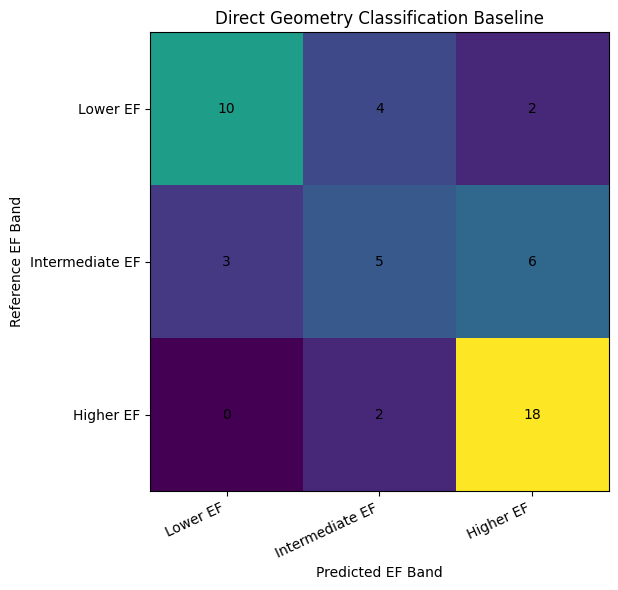

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3B_direct_baseline/plots/direct_baseline_confusion_matrix.png


In [ ]:
# ================================================================
# PHASE 3B — CELL 11
# CONFUSION MATRIX VISUALIZATION
# ================================================================

fig, ax = plt.subplots(
    figsize=(7, 6)
)

image = ax.imshow(
    direct_cm
)

ax.set_xticks(
    np.arange(len(CLASS_ORDER))
)

ax.set_yticks(
    np.arange(len(CLASS_ORDER))
)

display_labels = [
    "Lower EF",
    "Intermediate EF",
    "Higher EF"
]

ax.set_xticklabels(
    display_labels,
    rotation=25,
    ha="right"
)

ax.set_yticklabels(
    display_labels
)

ax.set_xlabel(
    "Predicted EF Band"
)

ax.set_ylabel(
    "Reference EF Band"
)

ax.set_title(
    "Direct Geometry Classification Baseline"
)


# Add counts inside cells
threshold = (
    direct_cm.max() / 2
)

for i in range(
    direct_cm.shape[0]
):

    for j in range(
        direct_cm.shape[1]
    ):

        value = direct_cm[i, j]

        ax.text(
            j,
            i,
            str(value),
            ha="center",
            va="center"
        )


fig.tight_layout()


CONFUSION_MATRIX_PATH = (
    P3B_PLOT_DIR /
    "direct_baseline_confusion_matrix.png"
)

fig.savefig(
    CONFUSION_MATRIX_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("Saved:")
print(CONFUSION_MATRIX_PATH)

In [ ]:
# ================================================================
# PHASE 3B — CELL 12
# TWO-CLASS-JUMP ERROR ANALYSIS
# ================================================================

severe_error_df = (
    phase3B_df.loc[
        phase3B_df[
            "transition_type"
        ]
        ==
        "Two_class_error"
    ]
    .copy()
)


assert len(severe_error_df) == 2, (
    f"Expected 2 two-class errors, "
    f"found {len(severe_error_df)}."
)


# ---------------------------------------------------------------
# SELECT AVAILABLE QUANTITATIVE COLUMNS
# ---------------------------------------------------------------

candidate_columns = [

    "patient_id",
    "image_quality",

    "reference_EF_pct",
    "GT_EF_pct",
    "PRED_EF_pct",

    "GT_ED_area_mm2",
    "PRED_ED_area_mm2",

    "GT_ES_area_mm2",
    "PRED_ES_area_mm2",

    "GT_ED_length_mm",
    "PRED_ED_length_mm",

    "GT_ES_length_mm",
    "PRED_ES_length_mm",

    "GT_EDV_ml",
    "PRED_EDV_ml",

    "GT_ESV_ml",
    "PRED_ESV_ml",

    "GT_SV_ml",
    "PRED_SV_ml",

    "ED_area_relative_error_pct",
    "ES_area_relative_error_pct",

    "reference_class",
    "predicted_class"
]


available_columns = [
    column
    for column in candidate_columns
    if column in severe_error_df.columns
]


print("=" * 72)
print("TWO-CLASS-JUMP FAILURE CASES")
print("=" * 72)

print(
    "\nThese are the only cases that jumped "
    "directly from Lower EF to Higher EF."
)

display(
    severe_error_df[
        available_columns
    ].round(3)
)


# ---------------------------------------------------------------
# EF ERROR DECOMPOSITION FOR THESE CASES
# ---------------------------------------------------------------

severe_error_df[
    "reference_to_GT_geometry_EF_error_pp"
] = (
    severe_error_df[
        "GT_EF_pct"
    ]
    -
    severe_error_df[
        "reference_EF_pct"
    ]
)


severe_error_df[
    "GT_geometry_to_PRED_EF_error_pp"
] = (
    severe_error_df[
        "PRED_EF_pct"
    ]
    -
    severe_error_df[
        "GT_EF_pct"
    ]
)


severe_error_df[
    "reference_to_PRED_EF_error_pp"
] = (
    severe_error_df[
        "PRED_EF_pct"
    ]
    -
    severe_error_df[
        "reference_EF_pct"
    ]
)


decomposition_columns = [

    "patient_id",

    "reference_EF_pct",
    "GT_EF_pct",
    "PRED_EF_pct",

    "reference_to_GT_geometry_EF_error_pp",
    "GT_geometry_to_PRED_EF_error_pp",
    "reference_to_PRED_EF_error_pp",

    "reference_class",
    "predicted_class"
]


print(
    "\nEF error decomposition:"
)

display(
    severe_error_df[
        decomposition_columns
    ].round(3)
)


SEVERE_ERROR_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_two_class_errors.csv"
)


severe_error_df.to_csv(
    SEVERE_ERROR_PATH,
    index=False
)


print("\nSaved:")
print(SEVERE_ERROR_PATH)

TWO-CLASS-JUMP FAILURE CASES

These are the only cases that jumped directly from Lower EF to Higher EF.


,patient_id,image_quality,reference_EF_pct,GT_EF_pct,PRED_EF_pct,GT_SV_ml,PRED_SV_ml,ED_area_relative_error_pct,ES_area_relative_error_pct,reference_class,predicted_class
33,patient0217,Good,19.0,67.673,61.795,53.723,49.682,-3.731,12.735,Lower_EF,Higher_EF
42,patient0072,Medium,38.0,47.885,53.532,61.203,56.423,-9.850,-15.561,Lower_EF,Higher_EF



EF error decomposition:


,patient_id,reference_EF_pct,GT_EF_pct,PRED_EF_pct,reference_to_GT_geometry_EF_error_pp,GT_geometry_to_PRED_EF_error_pp,reference_to_PRED_EF_error_pp,reference_class,predicted_class
33,patient0217,19.0,67.673,61.795,48.673,-5.878,42.795,Lower_EF,Higher_EF
42,patient0072,38.0,47.885,53.532,9.885,5.647,15.532,Lower_EF,Higher_EF



Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3B_direct_baseline/tables/direct_baseline_two_class_errors.csv


In [ ]:
# ================================================================
# PHASE 3B — CELL 13
# SAVE BASELINE TABLES
# ================================================================

SUMMARY_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_summary.csv"
)

PER_CLASS_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_per_class_metrics.csv"
)

CONFUSION_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_confusion_matrix.csv"
)

PATIENT_RESULTS_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_patient_results.csv"
)

BOUNDARY_PATH = (
    P3B_TABLE_DIR /
    "direct_baseline_boundary_analysis.csv"
)


direct_summary_df.to_csv(
    SUMMARY_PATH,
    index=False
)

per_class_metrics_df.to_csv(
    PER_CLASS_PATH,
    index=False
)

direct_cm_df.to_csv(
    CONFUSION_PATH
)

phase3B_df.to_csv(
    PATIENT_RESULTS_PATH,
    index=False
)

boundary_group_summary.to_csv(
    BOUNDARY_PATH,
    index=False
)


print("=" * 72)
print("PHASE 3B TABLES SAVED")
print("=" * 72)

for path in [
    SUMMARY_PATH,
    PER_CLASS_PATH,
    CONFUSION_PATH,
    PATIENT_RESULTS_PATH,
    BOUNDARY_PATH
]:
    print("✓", path.name)

PHASE 3B TABLES SAVED
✓ direct_baseline_summary.csv
✓ direct_baseline_per_class_metrics.csv
✓ direct_baseline_confusion_matrix.csv
✓ direct_baseline_patient_results.csv
✓ direct_baseline_boundary_analysis.csv


In [ ]:
# ================================================================
# PHASE 3B — CELL 14
# FINAL DIRECT-BASELINE RECORD AND FREEZE
# ================================================================

PHASE3B_RECORD_PATH = (
    P3B_CONFIG_DIR /
    "phase3B_direct_baseline_record.json"
)


phase3B_record = {

    # ------------------------------------------------------------
    # GENERAL
    # ------------------------------------------------------------

    "phase":
        "Phase 3B — Direct Geometry Classification Baseline",

    "status":
        "COMPLETE_AND_FROZEN",

    "task":
        (
            "Direct three-class EF-based functional classification "
            "using the frozen Phase 2 predicted EF."
        ),

    "evaluation_partition": {
        "split": "test",
        "n_patients": 50
    },

    "method": (
        "CAMUS reference EF was converted to the frozen Phase 3A "
        "EF bands and compared with the class obtained by applying "
        "the identical fixed bands to the frozen Phase 2 predicted EF. "
        "No classifier was trained."
    ),


    # ------------------------------------------------------------
    # FROZEN CLASS DEFINITION
    # ------------------------------------------------------------

    "class_definition": {

        "Lower_EF":
            "EF <= 40%",

        "Intermediate_EF":
            "40% < EF < 50%",

        "Higher_EF":
            "EF >= 50%"
    },

    "terminology_note":
        (
            "These labels represent EF-based functional bands "
            "for an assistive, non-diagnostic research system "
            "and are not standalone heart-failure diagnoses."
        ),


    # ------------------------------------------------------------
    # REFERENCE DISTRIBUTION
    # ------------------------------------------------------------

    "reference_distribution": {

        "Lower_EF": 16,
        "Intermediate_EF": 14,
        "Higher_EF": 20
    },


    # ------------------------------------------------------------
    # PREDICTED DISTRIBUTION
    # ------------------------------------------------------------

    "predicted_distribution": {

        "Lower_EF": 13,
        "Intermediate_EF": 11,
        "Higher_EF": 26
    },


    # ------------------------------------------------------------
    # PRIMARY PERFORMANCE
    # ------------------------------------------------------------

    "performance": {

        "accuracy":
            0.6600,

        "balanced_accuracy":
            0.6274,

        "macro_F1":
            0.6241,

        "weighted_F1":
            0.6457,

        "cohen_kappa":
            0.4747,

        "correct_patients":
            33,

        "incorrect_patients":
            17
    },


    # ------------------------------------------------------------
    # PER-CLASS PERFORMANCE
    # ------------------------------------------------------------

    "per_class_performance": {

        "Lower_EF": {
            "precision": 0.7692,
            "recall": 0.6250,
            "F1": 0.6897,
            "support": 16
        },

        "Intermediate_EF": {
            "precision": 0.4545,
            "recall": 0.3571,
            "F1": 0.4000,
            "support": 14
        },

        "Higher_EF": {
            "precision": 0.6923,
            "recall": 0.9000,
            "F1": 0.7826,
            "support": 20
        }
    },


    # ------------------------------------------------------------
    # CONFUSION MATRIX
    # ------------------------------------------------------------

    "confusion_matrix": {

        "class_order": [
            "Lower_EF",
            "Intermediate_EF",
            "Higher_EF"
        ],

        "matrix": [
            [10, 4, 2],
            [3, 5, 6],
            [0, 2, 18]
        ]
    },


    # ------------------------------------------------------------
    # ERROR TRANSITIONS
    # ------------------------------------------------------------

    "transition_analysis": {

        "total_errors":
            17,

        "adjacent_class_errors":
            15,

        "two_class_errors":
            2,

        "adjacent_error_fraction_pct":
            88.24,

        "predicted_higher_band":
            12,

        "predicted_lower_band":
            5,

        "exact_transitions": {

            "Lower_to_Intermediate": 4,
            "Lower_to_Higher": 2,

            "Intermediate_to_Lower": 3,
            "Intermediate_to_Higher": 6,

            "Higher_to_Intermediate": 2,
            "Higher_to_Lower": 0
        }
    },


    # ------------------------------------------------------------
    # BOUNDARY ANALYSIS
    # ------------------------------------------------------------

    "boundary_analysis": {

        "correct": {
            "n": 33,
            "mean_distance_pp": 7.000,
            "median_distance_pp": 6.000
        },

        "incorrect": {
            "n": 17,
            "mean_distance_pp": 5.647,
            "median_distance_pp": 4.000
        },

        "mann_whitney_U":
            331.0,

        "two_sided_p_value":
            0.303953,

        "interpretation":
            (
                "Misclassified patients were descriptively closer "
                "to the nearest 40% or 50% EF boundary, but the "
                "difference was not statistically significant in "
                "this 50-patient evaluation sample. Boundary "
                "proximity alone therefore did not explain all "
                "classification errors."
            ),

        "analysis_type":
            "descriptive post-hoc locked-baseline analysis",

        "used_for_threshold_tuning":
            False
    },


    # ------------------------------------------------------------
    # TWO-CLASS-JUMP FAILURE ANALYSIS
    # ------------------------------------------------------------

    "two_class_jump_analysis": {

        "n_cases":
            2,

        "patient0217": {

            "image_quality":
                "Good",

            "reference_EF_pct":
                19.0,

            "GT_geometry_EF_pct":
                67.673,

            "predicted_geometry_EF_pct":
                61.795,

            "reference_to_GT_geometry_error_pp":
                48.673,

            "GT_geometry_to_predicted_error_pp":
                -5.878,

            "reference_to_predicted_error_pp":
                42.795,

            "transition":
                "Lower_EF -> Higher_EF",

            "interpretation":
                (
                    "The dominant disagreement occurred before "
                    "segmentation propagation: even GT-mask geometry "
                    "produced an EF far above the CAMUS reference EF. "
                    "The segmentation-derived EF was slightly lower "
                    "than GT geometry. This case is therefore "
                    "primarily a reference-versus-geometric-method "
                    "disagreement rather than a segmentation-driven "
                    "classification failure."
                )
        },

        "patient0072": {

            "image_quality":
                "Medium",

            "reference_EF_pct":
                38.0,

            "GT_geometry_EF_pct":
                47.885,

            "predicted_geometry_EF_pct":
                53.532,

            "reference_to_GT_geometry_error_pp":
                9.885,

            "GT_geometry_to_predicted_error_pp":
                5.647,

            "reference_to_predicted_error_pp":
                15.532,

            "transition":
                "Lower_EF -> Higher_EF",

            "interpretation":
                (
                    "Both reference-versus-geometry disagreement "
                    "and segmentation propagation contributed to "
                    "the final two-class transition."
                )
        }
    },


    # ------------------------------------------------------------
    # MAIN FINDINGS
    # ------------------------------------------------------------

    "main_findings": [

        (
            "The direct frozen quantitative pipeline achieved "
            "66.0% exact three-class agreement with the reference "
            "EF-based functional bands."
        ),

        (
            "Higher EF showed the highest recall at 90.0%, while "
            "Intermediate EF was the most difficult class with "
            "35.7% recall and F1 of 0.400."
        ),

        (
            "Fifteen of seventeen classification errors (88.24%) "
            "were adjacent-band errors."
        ),

        (
            "Twelve of seventeen misclassified patients were "
            "assigned to a higher EF band than their reference band."
        ),

        (
            "Boundary proximity alone did not adequately explain "
            "classification disagreement."
        ),

        (
            "The two largest class-jump errors had different error "
            "sources, demonstrating that end-to-end classification "
            "failure cannot be attributed solely to segmentation."
        )
    ],


    # ------------------------------------------------------------
    # METHODOLOGICAL INTEGRITY
    # ------------------------------------------------------------

    "methodological_integrity": {

        "classifier_trained":
            False,

        "EF_boundaries_modified":
            False,

        "segmentation_modified":
            False,

        "phase2_geometry_modified":
            False,

        "bias_correction_applied":
            False,

        "calibration_applied":
            False,

        "patients_removed":
            False,

        "test_based_tuning":
            False
    },


    # ------------------------------------------------------------
    # LIMITATIONS
    # ------------------------------------------------------------

    "limitations": [

        (
            "The evaluation contains only 50 patients."
        ),

        (
            "The Intermediate EF band spans a relatively narrow "
            "range and is sensitive to quantitative EF disagreement."
        ),

        (
            "Predicted EF inherits both segmentation error and "
            "single-plane geometry/reference-method disagreement."
        ),

        (
            "The evaluation partition had historical pilot exposure "
            "and is not described as a pristine external test set."
        )
    ],


    # ------------------------------------------------------------
    # FREEZE
    # ------------------------------------------------------------

    "phase3B_frozen":
        True,

    "post_evaluation_threshold_tuning":
        False,

    "next_phase":
        "Phase 3C — Learned Classifier Development"
}


# ================================================================
# SAVE RECORD
# ================================================================

with open(
    PHASE3B_RECORD_PATH,
    "w"
) as f:

    json.dump(
        phase3B_record,
        f,
        indent=2
    )


print("=" * 72)
print("PHASE 3B — FINAL RECORD")
print("=" * 72)

print("\nStatus:")
print("COMPLETE AND FROZEN")

print("\nDirect baseline:")
print("Accuracy          : 66.00%")
print("Balanced Accuracy : 62.74%")
print("Macro F1          : 0.6241")
print("Cohen's Kappa     : 0.4747")

print("\nErrors:")
print("Adjacent          : 15 / 17")
print("Two-class         : 2 / 17")

print("\nBoundary analysis:")
print("p-value           : 0.303953")
print("Threshold tuning  : NONE")

print("\nSevere errors:")
print("patient0217       : primarily geometry/reference disagreement")
print("patient0072       : mixed geometry + segmentation contribution")

print("\n✓ No classifier trained")
print("✓ No EF threshold modified")
print("✓ No patients removed")
print("✓ No post-test tuning")
print("✓ Phase 3B frozen")

print("\nSaved:")
print(PHASE3B_RECORD_PATH)

PHASE 3B — FINAL RECORD

Status:
COMPLETE AND FROZEN

Direct baseline:
Accuracy          : 66.00%
Balanced Accuracy : 62.74%
Macro F1          : 0.6241
Cohen's Kappa     : 0.4747

Errors:
Adjacent          : 15 / 17
Two-class         : 2 / 17

Boundary analysis:
p-value           : 0.303953
Threshold tuning  : NONE

Severe errors:
patient0217       : primarily geometry/reference disagreement
patient0072       : mixed geometry + segmentation contribution

✓ No classifier trained
✓ No EF threshold modified
✓ No patients removed
✓ No post-test tuning
✓ Phase 3B frozen

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase3_classification/phase3B_direct_baseline/configs/phase3B_direct_baseline_record.json
